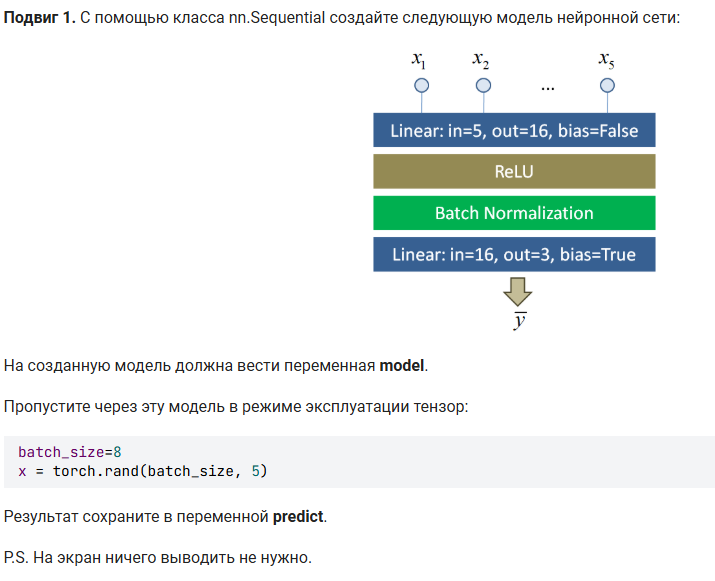

In [16]:
import torch
import torch.nn as nn

batch_size=8
x = torch.rand(batch_size, 5) # тензор x в программе не менять

model = nn.Sequential(
        nn.Linear(5, 16, bias=False),
        nn.ReLU(),
        nn.BatchNorm1d(16),
        nn.Linear(16, 3)
)

# model = nn.Sequential()
# model.add_module('layer1', nn.Linear(5, 15, bias=False))
# model.add_module('act', nn.ReLU())
# model.add_module('bn', nn.BatchNorm1d(15))
# model.add_module('layer2', nn.Linear(16, 3))


# здесь продолжайте программу
model.eval()
predict = model(x)

In [14]:
model.__dict__

{'training': True,
 '_parameters': {},
 '_buffers': {},
 '_non_persistent_buffers_set': set(),
 '_backward_pre_hooks': OrderedDict(),
 '_backward_hooks': OrderedDict(),
 '_is_full_backward_hook': None,
 '_forward_hooks': OrderedDict(),
 '_forward_hooks_with_kwargs': OrderedDict(),
 '_forward_hooks_always_called': OrderedDict(),
 '_forward_pre_hooks': OrderedDict(),
 '_forward_pre_hooks_with_kwargs': OrderedDict(),
 '_state_dict_hooks': OrderedDict(),
 '_state_dict_pre_hooks': OrderedDict(),
 '_load_state_dict_pre_hooks': OrderedDict(),
 '_load_state_dict_post_hooks': OrderedDict(),
 '_modules': {'0': Linear(in_features=5, out_features=15, bias=False),
  '1': ReLU(),
  '2': BatchNorm1d(15, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True),
  '3': Linear(in_features=16, out_features=3, bias=True)}}

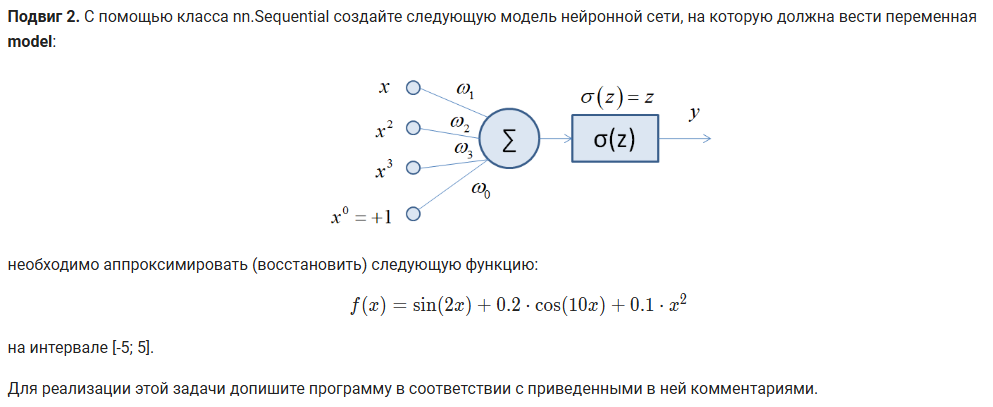

In [5]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

model = nn.Sequential(nn.Linear(3, 1, bias=True)) # пропишите модель нейронной сети

# создание обучающей выборки
_x = torch.arange(-5, 5, 0.1)
data_y = torch.sin(2 * _x) + 0.2 * torch.cos(10 * _x) + 0.1 * _x ** 2

_x.unsqueeze_(-1)
data_x = torch.cat([_x, _x ** 2, _x ** 3], dim=1)
ds = data.TensorDataset(data_x, data_y)

epochs = 20 # число эпох обучения
batch_size = 8 # размер батча

train_data = data.DataLoader(ds, batch_size=batch_size, shuffle=True) # создать объект класса DataLoader для датасета ds с размером пакетов batch_size и перемешиванием образов выборки

optimizer = optim.RMSprop(model.parameters(), lr=0.01) # создать оптимизатор RMSprop для обучения модели с шагом обучения 0.01
loss_func = nn.MSELoss() # создать функцию потерь с помощью класса MSELoss


# перевести модель в режим обучения
model.train()
for _e in range(epochs): # итерации по эпохам
    for x_train, y_train in train_data:
        predict = model(x_train).squeeze(1) # вычислить прогноз модели для данных x_train
        # print(predict.shape, y_train.shape)
        loss =  loss_func(predict, y_train) # вычислить значение функции потерь
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# перевести модель в режим эксплуатации
model.eval()
# выполнить прогноз модели по всем данным выборки (d_train.data)
predict = model(data_x).squeeze(1)
Q = loss_func(predict, data_y).item() # вычислить потери с помощью loss_func по всем данным выборки; значение Q сохранить в виде вещественного числа

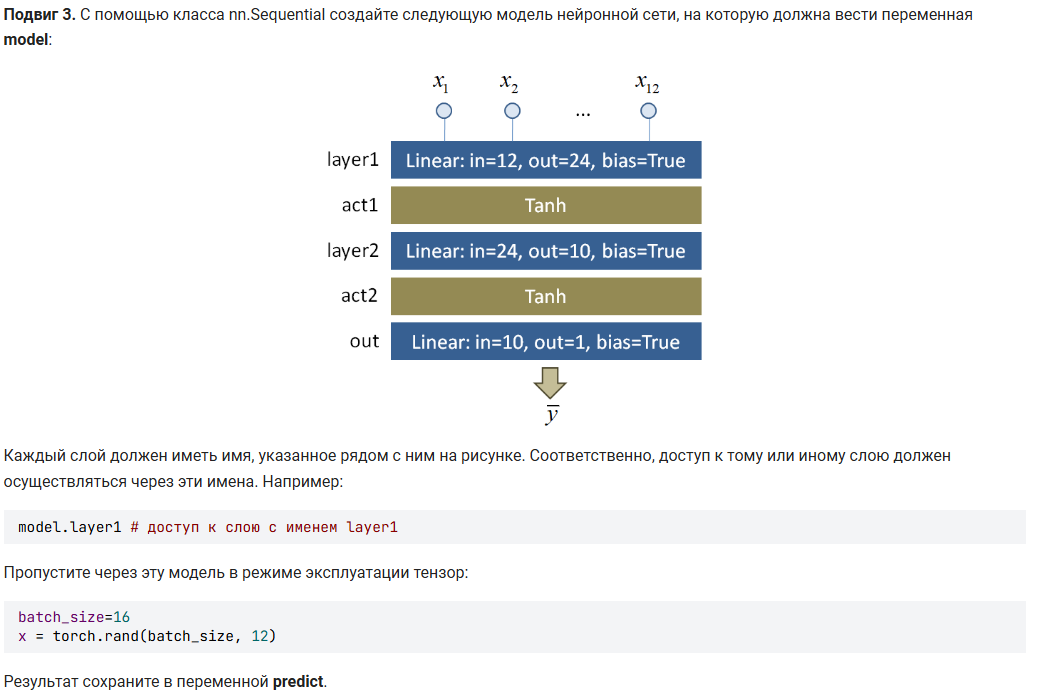

In [11]:
import torch
import torch.nn as nn

batch_size=16
x = torch.rand(batch_size, 12) # тензор x в программе не менять

# здесь продолжайте программу
model = nn.Sequential()
model.add_module('layer1', nn.Linear(12, 24, bias=True))
model.add_module('act1', nn.Tanh())
model.add_module('layer2', nn.Linear(24, 10, bias=True))
model.add_module('act2', nn.Tanh())
model.add_module('out', nn.Linear(10, 1, bias=True))

model.eval()
predict = model(x)

# with torch.no_grad():
#     predict = model(x)
    
predict


tensor([[0.2485],
        [0.1418],
        [0.1334],
        [0.1474],
        [0.1937],
        [0.1292],
        [0.1526],
        [0.0839],
        [0.1640],
        [0.1370],
        [0.1040],
        [0.0736],
        [0.0567],
        [0.1408],
        [0.2834],
        [0.1511]])

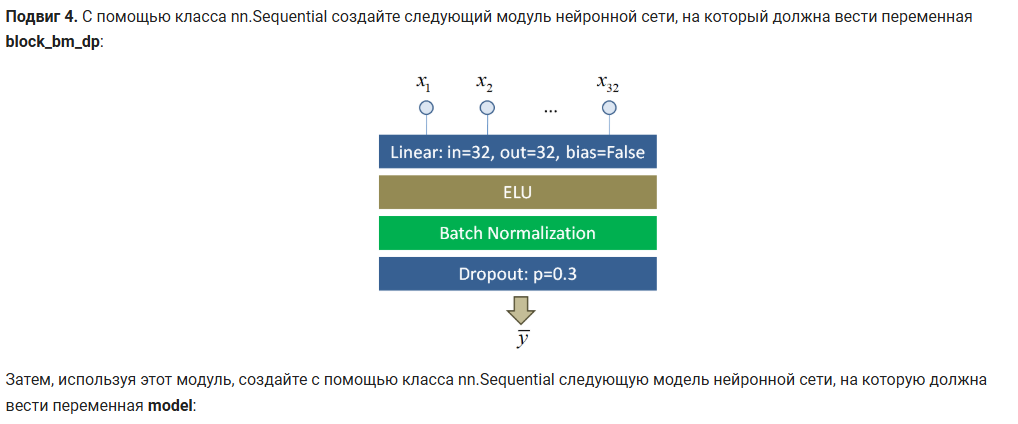

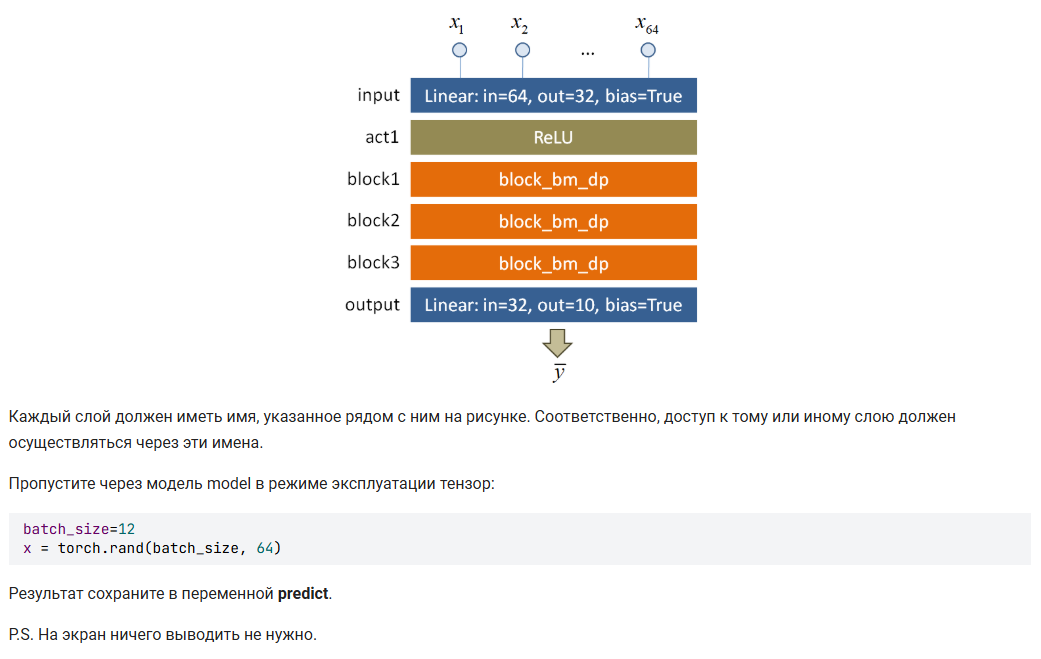

In [14]:
import torch
import torch.nn as nn

batch_size=12
x = torch.rand(batch_size, 64) # тензор x в программе не менять

# здесь продолжайте программу

block_bm_dp = nn.Sequential(
    nn.Linear(32, 32, bias=False),
    nn.ELU(),
    nn.BatchNorm1d(32),
    nn.Dropout(0.3)
)

model = nn.Sequential()
model.add_module('input', nn.Linear(64, 32, bias=True))
model.add_module('act1', nn.ReLU())
model.add_module('block1', block_bm_dp)
model.add_module('block2', block_bm_dp)
model.add_module('block3', block_bm_dp)
model.add_module('output', nn.Linear(32, 10, bias=True))

model.eval()
predict = model(x)


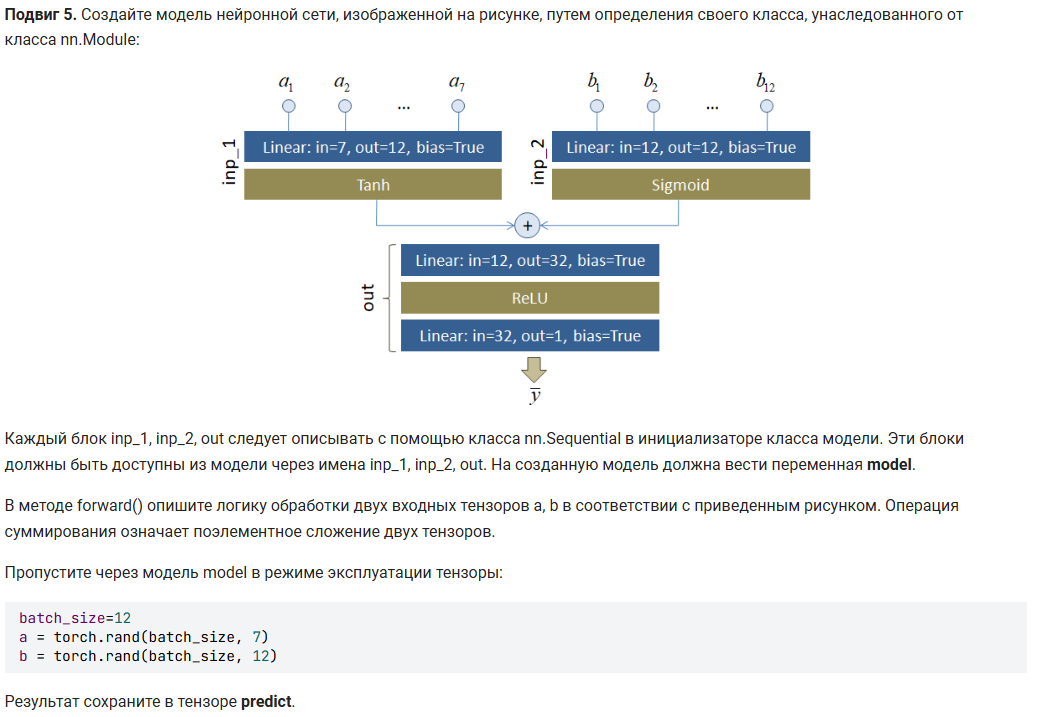

In [18]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.inp_1 = nn.Sequential(nn.Linear(7, 12, bias=True), nn.Tanh())
        self.inp_2 = nn.Sequential(nn.Linear(12, 12, bias=True), nn.Sigmoid())
        self.out = nn.Sequential(nn.Linear(12, 32, bias=True), nn.ReLU(), nn.Linear(32, 1, bias=True))

    def forward(self, a, b):
        a = self.inp_1(a)
        b = self.inp_2(b)
        res = self.out(a + b)
        # print(a.shape, b.shape, res.shape)
        return res

        

batch_size=12
a = torch.rand(batch_size, 7) # тензоры a, b в программе не менять
b = torch.rand(batch_size, 12)

# здесь продолжайте программу

model = MyModel()
model.eval()
predict = model(a, b)



torch.Size([12, 12]) torch.Size([12, 12]) torch.Size([12, 1])


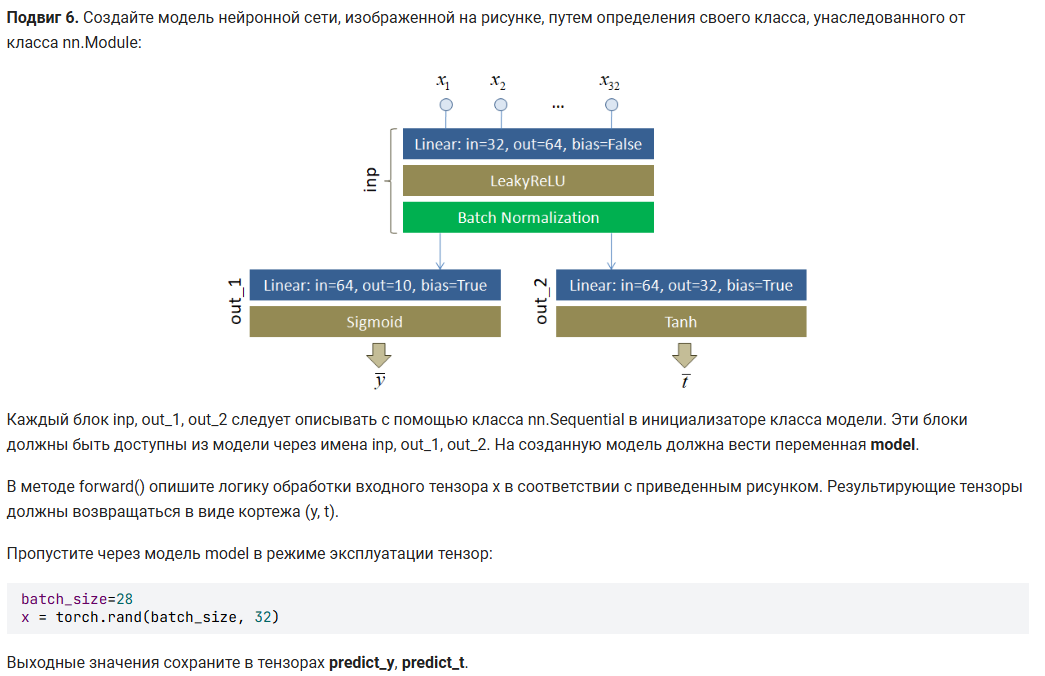
        
        








In [19]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(32, 64, bias=False), nn.LeakyReLU(), nn.BatchNorm1d(64))
        self.out_1 = nn.Sequential(nn.Linear(64, 10, bias=True), nn.Sigmoid())
        self.out_2 = nn.Sequential(nn.Linear(64, 32, bias=True), nn.Tanh())

    def forward(self, x):
        x = self.inp(x)
        out1 = self.out_1(x)
        out2 = self.out_2(x)
        return (out1, out2)
        

batch_size=28
x = torch.rand(batch_size, 32) # тензор x в программе не менять

# здесь продолжайте программу
model = MyModel()
model.eval()

predict_y, predict_t = model(x)

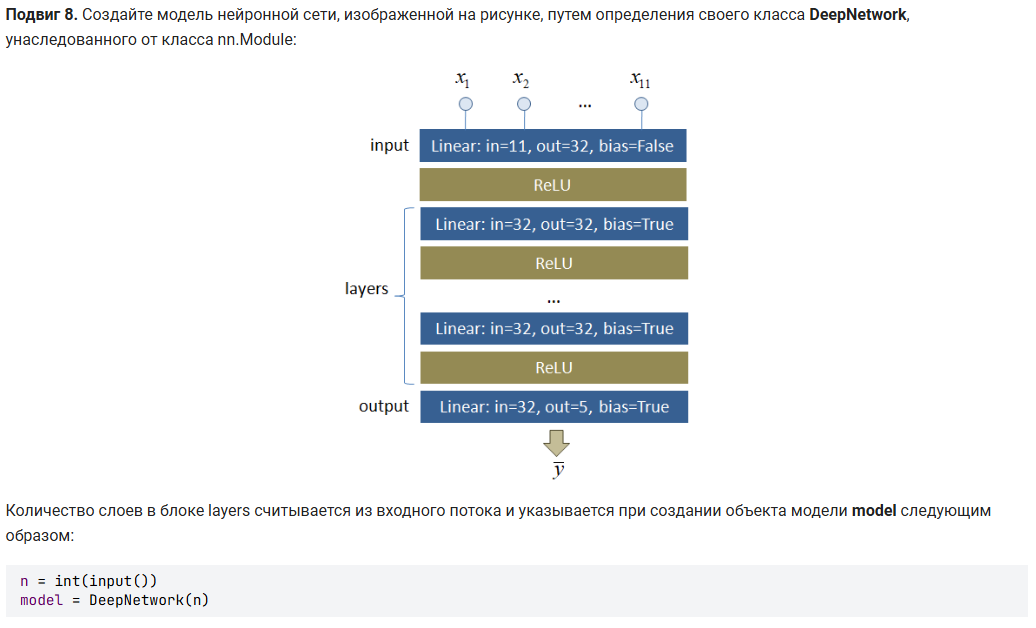

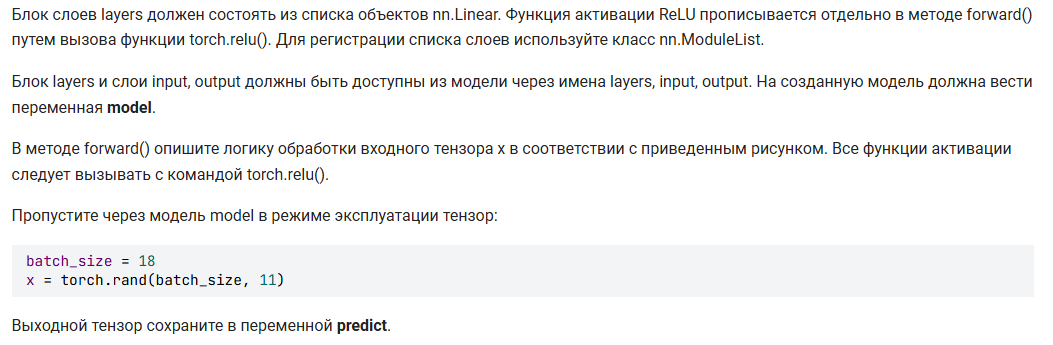

In [8]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class DeepNetwork(nn.Module):
    def __init__(self, num_layers):
        super().__init__()
        self.input = nn.Linear(11, 32, bias=False)
        self.layers = nn.ModuleList([nn.Linear(32, 32, bias=True) for _ in range(num_layers)])
        self.output = nn.Linear(32, 5, bias=True)

    def forward(self, x):
        x = self.input(x)
        x = torch.relu(x)
        for layer in self.layers:
            x = layer(x)
            x = torch.relu(x)
        x = self.output(x)
        return x
        

n = int(input()) # это значение в программе не менять
model = DeepNetwork(n)

batch_size = 18
x = torch.rand(batch_size, 11) # тензор x в программе не менять

# здесь продолжайте программу
model.eval()
predict = model(x)
predict

 5


tensor([[-0.0426, -0.1121,  0.0876,  0.1695, -0.1904],
        [-0.0429, -0.1116,  0.0873,  0.1680, -0.1906],
        [-0.0429, -0.1122,  0.0877,  0.1687, -0.1907],
        [-0.0429, -0.1111,  0.0869,  0.1670, -0.1902],
        [-0.0419, -0.1113,  0.0867,  0.1680, -0.1904],
        [-0.0421, -0.1120,  0.0874,  0.1683, -0.1906],
        [-0.0425, -0.1117,  0.0874,  0.1692, -0.1900],
        [-0.0420, -0.1124,  0.0875,  0.1686, -0.1909],
        [-0.0418, -0.1120,  0.0874,  0.1679, -0.1911],
        [-0.0426, -0.1117,  0.0872,  0.1675, -0.1904],
        [-0.0429, -0.1115,  0.0873,  0.1683, -0.1904],
        [-0.0430, -0.1112,  0.0870,  0.1682, -0.1899],
        [-0.0419, -0.1119,  0.0874,  0.1682, -0.1911],
        [-0.0431, -0.1118,  0.0874,  0.1681, -0.1906],
        [-0.0417, -0.1123,  0.0876,  0.1685, -0.1912],
        [-0.0429, -0.1117,  0.0873,  0.1689, -0.1904],
        [-0.0431, -0.1116,  0.0874,  0.1682, -0.1902],
        [-0.0424, -0.1121,  0.0875,  0.1689, -0.1905]],
       gr

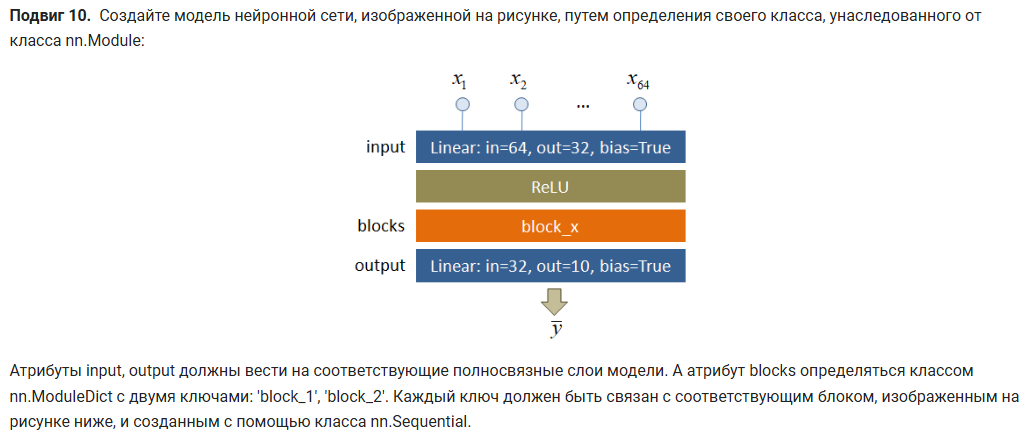

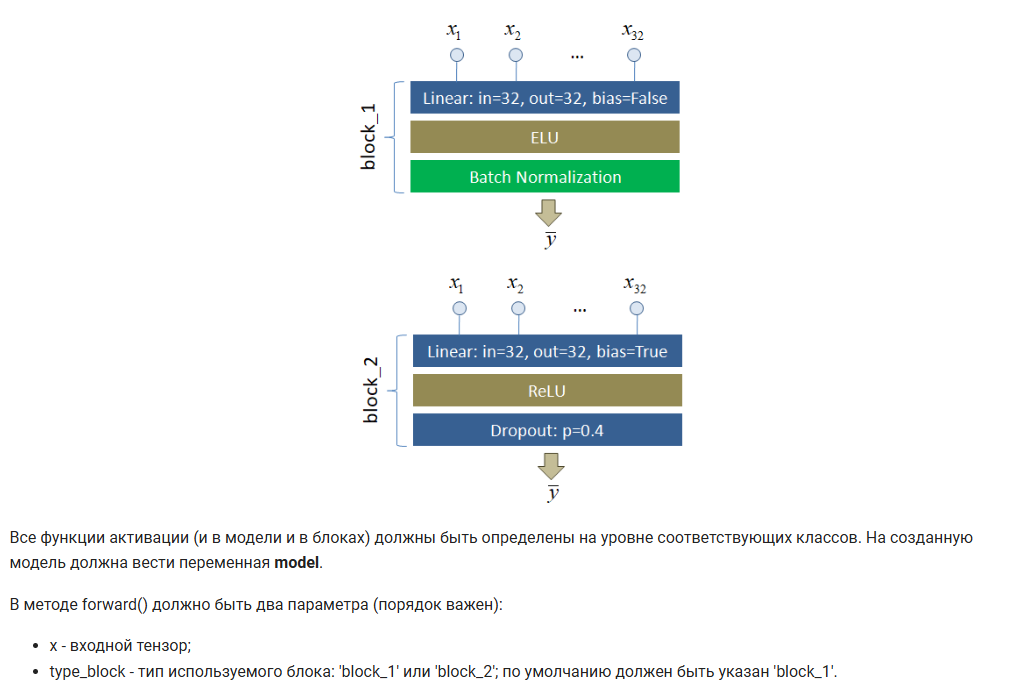

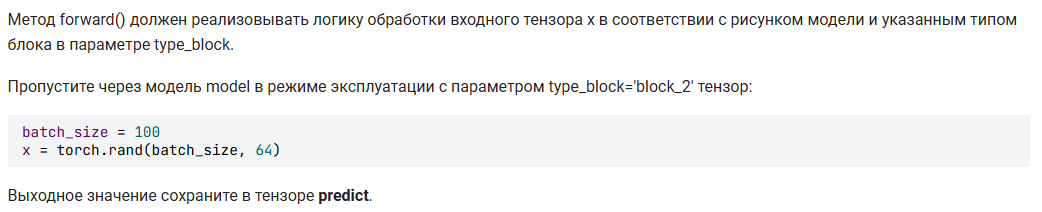

In [19]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.input = nn.Linear(64, 32, bias=True)
        self.blocks = nn.ModuleDict({
            'block_1': nn.Sequential(nn.Linear(32, 32, bias=False), nn.ELU(), nn.BatchNorm1d(32)),
            'block_2': nn.Sequential(nn.Linear(32, 32, bias=True), nn.ReLU(), nn.Dropout(0.4))
        })
        self.output = nn.Linear(32, 10, bias=True)

    def forward(self, x, type_block='block_1'):
        x = self.input(x)
        x = torch.relu(x)
        x = self.blocks[type_block](x)
        x = self.output(x)
        return x

batch_size = 100
x = torch.rand(batch_size, 64) # тензор x в программе не менять

# здесь продолжайте программу
model = MyModel()
model.eval()
predict = model(x, type_block='block_2')   
predict


tensor([[-0.1879, -0.0181, -0.0142, -0.1065, -0.1414,  0.0238,  0.1468, -0.0137,
          0.0640, -0.0391],
        [-0.1985, -0.0318, -0.0140, -0.0755, -0.1568,  0.0471,  0.1762, -0.0311,
          0.1359, -0.0281],
        [-0.1827, -0.0165,  0.0151, -0.1026, -0.1691,  0.0629,  0.1768,  0.0071,
          0.1265, -0.0232],
        [-0.1706, -0.0259,  0.0126, -0.1167, -0.1678,  0.0329,  0.1329, -0.0040,
          0.1055, -0.0116],
        [-0.1483, -0.0473, -0.0020, -0.0944, -0.1474,  0.0421,  0.1757,  0.0063,
          0.0945,  0.0160],
        [-0.2166,  0.0124, -0.0035, -0.1058, -0.1773,  0.0374,  0.1276, -0.0439,
          0.1086, -0.0420],
        [-0.1906, -0.0049,  0.0174, -0.1273, -0.1926,  0.0368,  0.1803, -0.0284,
          0.1338,  0.0229],
        [-0.2135, -0.0185, -0.0207, -0.1228, -0.1756,  0.0003,  0.1528, -0.0321,
          0.1070, -0.0205],
        [-0.1744, -0.0259,  0.0015, -0.1256, -0.1747,  0.0162,  0.1412, -0.0506,
          0.0907, -0.0113],
        [-0.1982, -

In [15]:
model

MyModel(
  (input): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
  )
  (blocks): ModuleDict(
    (block_1): Sequential(
      (0): Linear(in_features=32, out_features=32, bias=False)
      (1): ELU(alpha=1.0)
      (2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (block_2): Sequential(
      (0): Linear(in_features=32, out_features=32, bias=False)
      (1): ReLU()
      (2): Dropout(p=0.3, inplace=False)
    )
  )
  (output): Linear(in_features=32, out_features=10, bias=True)
)